# 08 · How the fire spread, day by day

**Question:** when did each part of the footprint burn?

**Data:** NASA **FIRMS** (Fire Information for Resource Management System) active-fire detections. Several times a day, satellites carrying the **VIIRS** sensor pass over and flag every 375 m pixel that is much hotter than its surroundings: a **hotspot**. Each hotspot has a position, a date and a time. Three satellites carry VIIRS (Suomi NPP, NOAA-20, NOAA-21), so together they see the fire about six times a day.

**Key:** FIRMS asks for a free **MAP_KEY** (like a library card). It is read from the `.env` file in the project folder, which is never published. Get one at https://firms.modaps.eosdis.nasa.gov/api/map_key/ and add the line `FIRMS_MAP_KEY=...` to `.env`.

In [1]:
import io
import geopandas as gpd
import pandas as pd
import requests
import shapely
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from common import *

FIRMS = "https://firms.modaps.eosdis.nasa.gov/api/area/csv"
SOURCES = ["VIIRS_SNPP_SP", "VIIRS_NOAA20_SP", "VIIRS_NOAA21_SP"]   # SP = final 'standard processing' quality
fire = pd.Timestamp(CFG["fire_start"])
area = ",".join(str(v) for v in CFG["bbox"])
raw_file = OUT / "firms_hotspots_raw.csv"

if raw_file.exists():                          # downloaded before: no key needed
    raw = pd.read_csv(raw_file)
else:
    key, parts = secret("FIRMS_MAP_KEY"), []
    for src in SOURCES:
        for start in [fire - pd.Timedelta(days=2), fire + pd.Timedelta(days=3), fire + pd.Timedelta(days=8)]:
            url = f"{FIRMS}/{key}/{src}/{area}/5/{start.date()}"     # at most 5 days per request
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            if r.text.startswith("latitude"):
                parts.append(pd.read_csv(io.StringIO(r.text)).assign(source=src))
    raw = pd.concat(parts, ignore_index=True)
    raw.to_csv(raw_file, index=False)
print(f"{len(raw)} hotspots in the AOI from {raw.acq_date.min()} to {raw.acq_date.max()}")

10118 hotspots in the AOI from 2026-07-22 to 2026-07-31


## 1. Keep the hotspots that belong to this fire
- **Time:** FIRMS gives times in UTC. Spain in summer is UTC+2, so a night pass at 01:30 UTC is 03:30 local time. We convert to local time before grouping by day.
- **Confidence:** drop detections marked low confidence (`l`).
- **Place:** keep hotspots within 1 km of our footprint. One VIIRS pixel is 375 m wide, so a hotspot's centre can sit a little outside the burn scar. Hotspots further away are other fires or hot surfaces.
- **Dates:** from ignition to 10 days later.

In [2]:
hs = raw.copy()
hs["utc"] = pd.to_datetime(hs.acq_date + " " + hs.acq_time.astype(str).str.zfill(4), format="%Y-%m-%d %H%M", utc=True)
hs["local"] = hs.utc.dt.tz_convert("Europe/Madrid")
hs["day"] = hs.local.dt.tz_localize(None).dt.normalize()
hs = gpd.GeoDataFrame(hs, geometry=gpd.points_from_xy(hs.longitude, hs.latitude), crs=4326).to_crs(CFG["crs"])

fp_gdf = gpd.read_file(need("burn_footprint.gpkg", "04"), layer="footprint_dissolved").to_crs(CFG["crs"])
fp = fp_gdf.union_all()
zone = fp.simplify(20).buffer(1000, resolution=4)   # simplify first: buffering every pixel edge is very slow
shapely.prepare(zone)
near = pd.Series(shapely.contains_xy(zone, hs.geometry.x, hs.geometry.y), index=hs.index)
keep = near & (hs.confidence != "l") & (hs.day >= fire) & (hs.day <= fire + pd.Timedelta(days=10))
print(f"Kept {keep.sum()} of {len(hs)}  (far from the footprint: {(~near).sum()}, low confidence: {(hs.confidence == 'l').sum()})")
hs = hs[keep].copy()
hs[["source", "local", "day", "frp", "confidence", "daynight", "geometry"]].assign(
    local=hs.local.astype(str)).to_file(OUT / "firms_hotspots.gpkg", driver="GPKG")
per_day = pd.crosstab(hs.day.dt.date, hs.source, margins=True, margins_name="total")
per_day

Kept 9476 of 10118  (far from the footprint: 47, low confidence: 596)


source,VIIRS_NOAA20_SP,VIIRS_NOAA21_SP,VIIRS_SNPP_SP,total
day,,,,
2026-07-22,2,23,62,87
2026-07-23,357,151,253,761
2026-07-24,659,466,523,1648
2026-07-25,800,1194,899,2893
2026-07-26,965,758,1210,2933
2026-07-27,346,304,430,1080
2026-07-28,22,24,22,68
2026-07-30,1,0,1,2
2026-07-31,2,2,0,4


## 2. Hotspots by day
Each dot is a hotspot, coloured by its local date. **FRP** (fire radiative power, in megawatts) measures how much heat the fire gave off: bigger means more intense.

First detection: 22 Jul 15:35 local, at 40.353 N, -4.741 E (VIIRS_NOAA21_SP)


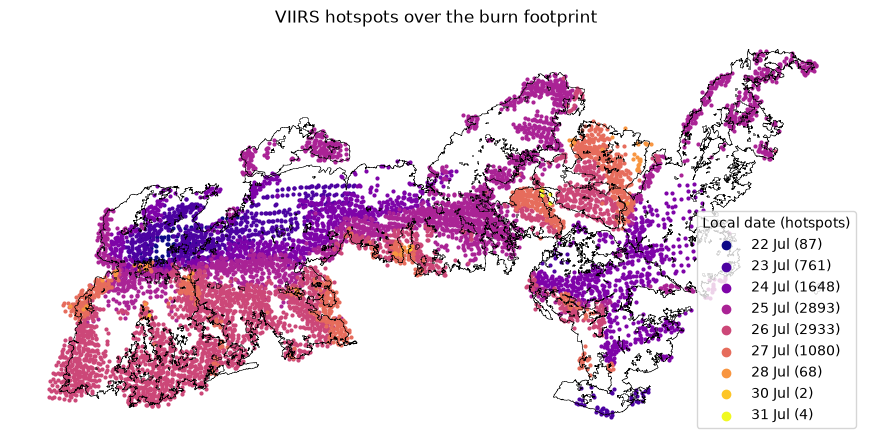

In [3]:
days = sorted(hs.day.unique())
cmap = plt.get_cmap("plasma", len(days))
fig, ax = plt.subplots(figsize=(11, 7))
fp_gdf.boundary.plot(ax=ax, color="black", lw=0.4)
for i, d in enumerate(days):
    sub = hs[hs.day == d]
    ax.scatter(sub.geometry.x, sub.geometry.y, s=4, color=cmap(i), label=f"{pd.Timestamp(d):%d %b} ({len(sub)})")
ax.legend(title="Local date (hotspots)", markerscale=3, loc="lower right")
ax.set_title("VIIRS hotspots over the burn footprint")
ax.set_axis_off()
fig.savefig(OUT / "step8_hotspots_by_day.png", dpi=150, bbox_inches="tight")

first = hs.sort_values("local").iloc[0]
lonlat = gpd.GeoSeries([first.geometry], crs=CFG["crs"]).to_crs(4326).iloc[0]
print(f"First detection: {first.local:%d %b %H:%M} local, at {lonlat.y:.3f} N, {lonlat.x:.3f} E ({first.source})")

## 3. From dots to a burn-date map
Hotspots are dots, but the footprint is a continuous area. A common way to fill the gaps is to give each burned pixel the date of its **nearest hotspot**, like giving every house the postcode of the nearest post office. We work on a 50 m grid and only accept a hotspot within 1.5 km, so far-off pixels stay undated.

**Caveat:** satellites pass only a few times a day and smoke or thick flames can hide hotspots, so this shows the general spread, not exact fire-front lines.

In [4]:
import rasterio

with rasterio.open(need("footprint_mask.tif", "04")) as src:
    m10, crs = src.read(1) == 1, src.crs
    f = 5                                                 # 10 m -> 50 m: 5 x 5 blocks
    H, W = m10.shape[0] // f, m10.shape[1] // f
    frac = m10[:H * f, :W * f].reshape(H, f, W, f).mean(axis=(1, 3))  # share of each block that burned
    mask = frac > 0
    tr = src.transform * src.transform.scale(f)
rows, cols = np.nonzero(mask)
xs, ys = rasterio.transform.xy(tr, rows, cols)
dist, idx = cKDTree(np.c_[hs.geometry.x, hs.geometry.y]).query(np.c_[xs, ys], distance_upper_bound=1500)
ok = np.isfinite(dist)
day_num = np.zeros(mask.shape, "uint8")                     # 0 = no date, 1 = ignition day, 2 = next day...
day_idx = ((hs.day.values - np.datetime64(fire)) // np.timedelta64(1, "D")).astype(int) + 1
day_num[rows[ok], cols[ok]] = day_idx[idx[ok]]
write_tif(OUT / "burn_date_50m.tif", day_num, tr, crs, nodata=0)

px_km2 = abs(tr.a * tr.e) / 1e6                      # area of one 50 m block; partly burned blocks count by their share
dates = [fire + pd.Timedelta(days=int(k) - 1) for k in range(1, day_num.max() + 1)]
daily = pd.DataFrame({"date": dates, "burned_km2": [frac[day_num == k].sum() * px_km2 for k in range(1, day_num.max() + 1)]})
daily["cumulative_km2"] = daily.burned_km2.cumsum()
daily["cumulative_pct"] = 100 * daily.cumulative_km2 / (frac.sum() * px_km2)
daily = daily[daily.burned_km2 > 0].round({"burned_km2": 1, "cumulative_km2": 1, "cumulative_pct": 1})
daily.to_csv(OUT / "step8_daily_progression.csv", index=False)
undated = 100 * frac[rows[~ok], cols[~ok]].sum() / frac.sum()
print(f"Footprint pixels with no hotspot within 1.5 km: {undated:.1f}%")
daily

Footprint pixels with no hotspot within 1.5 km: 1.1%


,date,burned_km2,cumulative_km2,cumulative_pct
0,2026-07-22,4.9,4.9,0.8
1,2026-07-23,61.3,66.2,10.7
2,2026-07-24,155.6,221.8,35.9
3,2026-07-25,200.2,422.0,68.3
4,2026-07-26,145.6,567.6,91.8
5,2026-07-27,38.3,605.9,98.0
6,2026-07-28,4.7,610.6,98.8
8,2026-07-30,0.1,610.7,98.8
9,2026-07-31,0.3,611.0,98.9


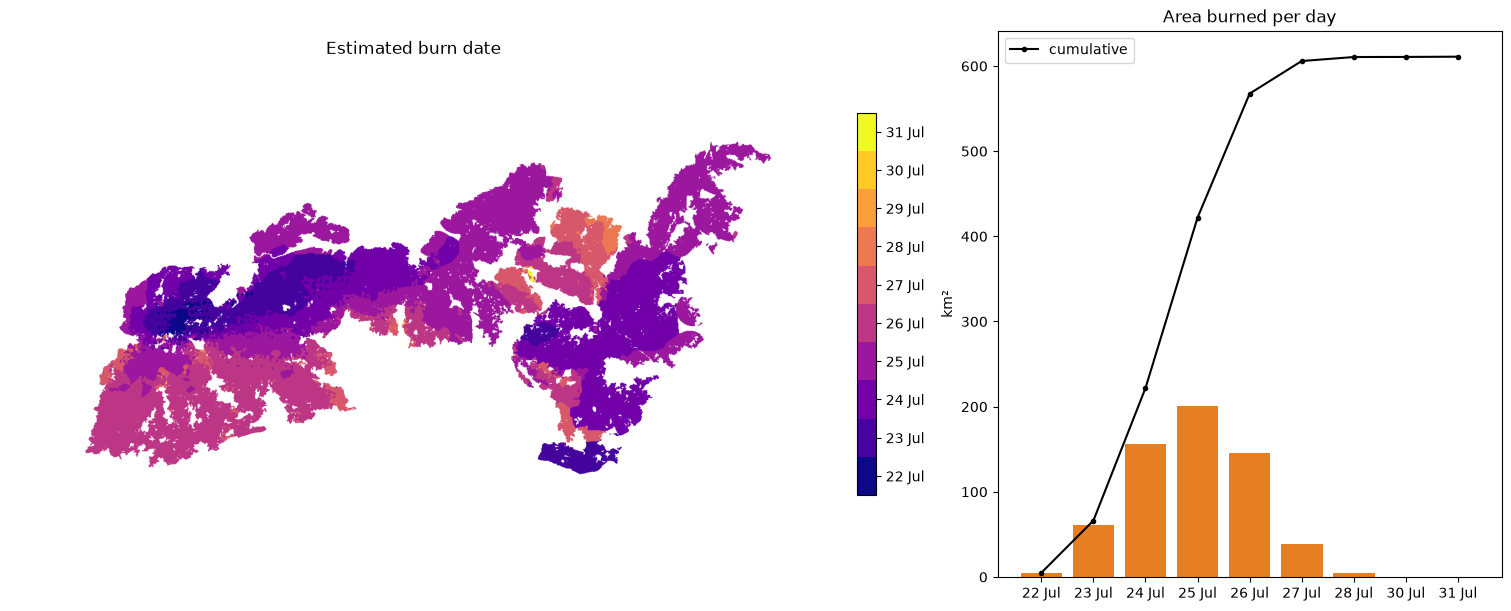

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.6, 1]}, constrained_layout=True)
shown = np.ma.masked_equal(day_num, 0)
x0, y0 = tr * (0, 0)
x1, y1 = tr * (mask.shape[1], mask.shape[0])
im = a1.imshow(shown, cmap=plt.get_cmap("plasma", day_num.max()), extent=[x0, x1, y1, y0],
               vmin=0.5, vmax=day_num.max() + 0.5)
cb = fig.colorbar(im, ax=a1, shrink=0.7, ticks=range(1, day_num.max() + 1))
cb.ax.set_yticklabels([f"{d:%d %b}" for d in dates])
a1.set_title("Estimated burn date"); a1.set_axis_off()
a2.bar(daily.date.dt.strftime("%d %b"), daily.burned_km2, color="#e67e22")
a2.plot(daily.date.dt.strftime("%d %b"), daily.cumulative_km2, "k-o", ms=3, label="cumulative")
a2.set_ylabel("km²"); a2.legend(); a2.set_title("Area burned per day")
fig.savefig(OUT / "step8_progression.png", dpi=150, bbox_inches="tight")

peak = daily.loc[daily.burned_km2.idxmax()]
save_json({"sources": SOURCES, "hotspots_used": int(len(hs)),
           "first_detection_local": f"{first.local:%Y-%m-%d %H:%M}",
           "first_detection_lonlat": [round(lonlat.x, 4), round(lonlat.y, 4)],
           "hotspots_per_day": {f"{pd.Timestamp(d):%Y-%m-%d}": int((hs.day == d).sum()) for d in days},
           "peak_day": f"{peak.date:%Y-%m-%d}", "peak_day_km2": float(peak.burned_km2),
           "pct_undated": round(undated, 1),
           "daily": [{"date": f"{r.date:%Y-%m-%d}", "burned_km2": float(r.burned_km2),
                      "cumulative_km2": float(r.cumulative_km2)} for r in daily.itertuples()]},
          "step8_progression.json")

## What you learned
- **Hotspots** are thermal alarms from satellites: a time and a place, but not an area.
- **Time zones** matter: always convert UTC to local time before grouping by day.
- **Nearest-neighbour interpolation** turns scattered points into a continuous map, with clear limits you should state.
- **Secrets** such as API keys belong in a `.env` file that stays out of Git, never in the notebook.

🎉 That's the full workflow. All results are in `outputs_madrid_avila/`.